# 02b · H1 power with the real extension values

Run this **after** `02_extension_models.ipynb`. It reads `results/models/m2/extras.csv` and reruns the H1 power simulation with the real alignment and d′ of the networks that survived the copy check.

- The simulation code below is `h1_power.py` (20 Nov 2026), pasted unchanged except for the command-line wrapper. Its grid contains both M = 14 and M = 14 + n, so one run gives both columns.
- It uses only predictors (alignment, d′, families). No outcome of any real model.
- About 25 minutes on a laptop CPU. The result is cached and reused unless `extras.csv` or the settings change.

The tables show power (the share of simulated studies in which the full H1 rule succeeds), averaged over ICC and r_xa, with the worst case in brackets, for the rule as written and for the calibrated (wild cluster) test. β = 0 rows are false-positive rates (should be near 2.5% or below).

In [1]:
import os, json, hashlib
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

REPO = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
OUT = os.path.join(REPO, "results", "models", "m2")
FIG_DIR = os.path.join(OUT, "figures")
os.makedirs(FIG_DIR, exist_ok=True)
EXTRAS_CSV = os.path.join(OUT, "extras.csv")
POWER_CSV = os.path.join(OUT, "h1_power_real_extras.csv")
POWER_REPS, POWER_BOOT, POWER_SEED = 800, 499, 1

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")

sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})

assert os.path.exists(EXTRAS_CSV), "run 02_extension_models.ipynb first"
extras = pd.read_csv(EXTRAS_CSV)
f02 = json.load(open(os.path.join(OUT, "facts_02.json")))
print("duplicate rule used by notebook 02:", f02.get("duplicate_rule", "NOT RECORDED"))
assert "shared weights" in f02.get("duplicate_rule", ""), \
    "extras.csv is from an older run of notebook 02 (no shared-weights test): rerun notebook 02 first"
assert extras.model.tolist() == f02["included"], "extras.csv and facts_02.json disagree: rerun notebook 02"
print(f"{len(extras)} extension networks -> {14 + len(extras)} models, "
      f"{f02['final_families']} families\n")
print(extras.to_string(index=False))
power_note = None if len(extras) else "no extension network survived the copy check: nothing to rerun, the set stays at 14"
if power_note:
    print(power_note)

duplicate rule used by notebook 02: RSA >= 0.98, or cosine median >= 0.99 and p01 >= 0.95, or cosine median >= 0.5 (shared weights; deviation 23 Nov 2026)
2 extension networks -> 16 models, 12 families

     model          family    align    dprime
 w600k_r50 R50-WebFace600K 0.098347 11.158462
IRV1-casia      IRV1-CASIA 0.257204  4.957504


## The simulation (`h1_power.py`, unchanged)

In [2]:
import argparse, itertools, time
import numpy as np
import pandas as pd

# ---------------------------------------------------------------- real predictors (14 core models)
CORE = pd.DataFrame({
    "model":  ["ArcFace18", "ArcFace34", "ArcFace50", "ArcFace100", "swinface", "FaceNet", "FaceNet512",
               "Dlib", "VGG-Face", "GhostFaceNet", "SFace", "DeepFace", "OpenFace", "DeepID"],
    "family": ["ArcFace"] * 4 + ["SwinFace", "FaceNet", "FaceNet", "Dlib", "VGG-Face", "GhostFaceNet",
               "SFace", "DeepFace", "OpenFace", "DeepID"],
    # alignment on USAFD-only trials (01_data_and_release, section 4; equals Models_alignment.pkl)
    "align":  [0.178198, 0.157336, 0.141943, 0.129864, 0.138980, 0.247798, 0.247877, 0.297108, 0.238400,
               0.190163, 0.176088, 0.167771, 0.178716, 0.117758],
    # d' on the CFD recognition pairs (01_data_and_release, section 5)
    "dprime": [6.2954, 8.0514, 8.6209, 9.5741, 7.2028, 4.6207, 4.1907, 3.2496, 4.0916, 3.3940, 3.3683,
               1.3214, 1.1059, 0.7770],
})

# Extension networks (sensitivity set minus Buffalo_L). Their alignment and d' are NOT computed yet.
# d' is a plausible guess from the architecture; alignment is drawn each replication from the
# inverted-U relation fitted to the 14 core models plus its residual scatter (see draw_extras).
EXTRA = pd.DataFrame({
    "model":  ["w600k_r50", "glintr100", "IRV1-casia", "IRV1-vggface2"],
    "family": ["R50-WebFace600K", "ArcFace", "IRV1-CASIA", "FaceNet"],  # family = backbone x training data
    "dprime": [9.3, 9.6, 4.8, 4.6],
})

SE_MAIN, SE_HOLD, RHO_NOISE = 0.004, 0.0066, 0.5   # estimation noise of L(m); share across models
DELTA_A = -0.005    # true effect of +1 SD mean trait accuracy on L(m) (absorbed by the covariate)


def zs(v):
    return (v - v.mean()) / v.std()


def fit_inverted_u(df):
    c = np.polyfit(df.dprime, df["align"], 2)
    resid = df["align"] - np.polyval(c, df.dprime)
    return c, resid.std(ddof=3)


def design(align, dprime, a):
    """Intercept, z(alignment), z(d'), z(d'^2 centred), z(mean trait accuracy)."""
    dc = dprime - dprime.mean()
    return np.column_stack([np.ones_like(align), zs(align), zs(dc), zs(dc ** 2), a])


def noise_chol(m, se, rho):
    cov = se ** 2 * ((1 - rho) * np.eye(m) + rho * np.ones((m, m)))
    return np.linalg.cholesky(cov)


def ols_coef(X, y):
    return np.linalg.lstsq(X, y, rcond=None)[0][1]


WEBB = np.array([-np.sqrt(1.5), -1.0, -np.sqrt(0.5), np.sqrt(0.5), 1.0, np.sqrt(1.5)])


def wild_cluster_p(rng, X, y, fam_idx, n_fam, boot):
    """One-sided (lower-tail) p-value for the alignment coefficient: wild cluster bootstrap-t,
    null imposed, Webb six-point weights, CR1 cluster-robust SE by family. Calibrated for few
    clusters (Webb 2014; MacKinnon & Webb 2017)."""
    m, k = X.shape
    G = np.zeros((n_fam, m)); G[fam_idx, np.arange(m)] = 1.0
    Q = np.linalg.pinv(X.T @ X); P = Q @ X.T
    adj = n_fam / (n_fam - 1) * (m - 1) / (m - k)

    def tstats(Y):                                  # Y: B x m
        b = Y @ P.T                                 # B x k
        e = Y - b @ X.T
        s = np.einsum("gm,bm,mk->bgk", G, e, X)     # cluster scores
        meat = np.einsum("bgk,bgl->bkl", s, s)
        v = np.einsum("i,bij,j->b", Q[1], meat, Q[1])
        return b[:, 1] / np.sqrt(adj * v)

    t_obs = tstats(y[None, :])[0]
    Xr = np.delete(X, 1, axis=1)                    # restricted model: alignment coefficient = 0
    yr_hat = Xr @ np.linalg.lstsq(Xr, y, rcond=None)[0]
    ur = y - yr_hat
    v = WEBB[rng.integers(0, 6, size=(boot, n_fam))][:, fam_idx]
    t_star = tstats(yr_hat[None, :] + v * ur[None, :])
    return (np.sum(t_star <= t_obs) + 1) / (boot + 1)


def one_rep(rng, align, dprime, fam_idx, n_fam, beta, sigma, icc, r_xa, boot, L_main, L_hold,
            omit=None):
    m = len(align)
    x = zs(align)
    a = r_xa * x + np.sqrt(1 - r_xa ** 2) * rng.standard_normal(m)     # mean trait accuracy (std)
    a = zs(a)
    u = rng.standard_normal(n_fam)[fam_idx] * sigma * np.sqrt(icc)
    e = rng.standard_normal(m) * sigma * np.sqrt(1 - icc)
    true_L = -beta * x + DELTA_A * a + u + e
    if omit is not None:                                               # omitted model-level confounder
        r_c, kappa = omit
        c = zs(r_c * x + np.sqrt(1 - r_c ** 2) * rng.standard_normal(m))
        true_L = true_L + kappa * sigma * c
    y = true_L + L_main @ rng.standard_normal(m)
    y_h = true_L + L_hold @ rng.standard_normal(m)
    X = design(align, dprime, a)

    # (1) two-level bootstrap: multinomial weights over families, fresh estimation noise
    w = rng.multinomial(n_fam, np.full(n_fam, 1 / n_fam), size=boot)[:, fam_idx].astype(float)  # B x m
    ys = y[None, :] + (L_main @ rng.standard_normal((m, boot))).T                                # B x m
    XtW = np.einsum("bm,mk->bkm", w, X)
    A = XtW @ X                                                                                  # B x k x k
    rhs = np.einsum("bkm,bm->bk", XtW, ys)
    coef = np.einsum("bij,bj->bi", np.linalg.pinv(A), rhs)[:, 1]
    lo, hi = np.percentile(coef, [2.5, 97.5])
    c1 = hi < 0
    # (2) leave one family out
    c2 = all(ols_coef(X[fam_idx != f], y[fam_idx != f]) < 0 for f in range(n_fam))
    # (3) hold-out direction
    c3 = ols_coef(X, y_h) < 0
    # (1') calibrated alternative to (1): wild cluster bootstrap-t, one-sided p < 0.025
    c1w = wild_cluster_p(rng, X, y, fam_idx, n_fam, boot) < 0.025
    return c1, c2, c3, c1w


def run(reps, boot, seed, out, extras=None):
    rng = np.random.default_rng(seed)
    global EXTRA
    fixed = False
    if extras:
        EXTRA = pd.read_csv(extras)[["model", "family", "align", "dprime"]]
        assert EXTRA[["align", "dprime"]].notna().all().all(), "extras.csv needs align and dprime for every row"
        fixed = True
        print(f"using REAL values for {len(EXTRA)} extension networks from {extras}")
    cU, rsd = fit_inverted_u(CORE)
    print(f"inverted-U fit on core: align = {cU[0]:.5f} d'^2 + {cU[1]:.4f} d' + {cU[2]:.4f}; "
          f"residual SD {rsd:.4f}")
    sets = {}
    M_EXT = 14 + len(EXTRA)
    for M in (14, M_EXT):
        df = CORE if M == 14 else pd.concat([CORE, EXTRA], ignore_index=True)
        fams = {f: i for i, f in enumerate(dict.fromkeys(df.family))}
        sets[M] = (df, np.array([fams[f] for f in df.family]), len(fams))
        print(f"M={M}: {len(df)} models, {len(fams)} families")

    grid = list(itertools.product((14, M_EXT), (0.005, 0.01, 0.02), (0.0, 0.3, 0.6), (0.0, 0.3, 0.6),
                                  (0.0, 0.005, 0.01, 0.02, 0.03)))
    extra_cases = []   # omitted-confounder check: see h1_power_omitted_confounder.csv (kappa = -0.5)
    rows, t0 = [], time.time()
    for k, (M, sigma, icc, r_xa, beta, *om) in enumerate([g + (None,) for g in grid] + extra_cases):
        omit = om[0] if om else None
        df, fam_idx, n_fam = sets[M]
        m = len(df)
        L_main, L_hold = noise_chol(m, SE_MAIN, RHO_NOISE), noise_chol(m, SE_HOLD, RHO_NOISE)
        hits = np.zeros((reps, 4), bool)
        for r in range(reps):
            if M == 14 or fixed:
                align = df["align"].to_numpy(dtype=float).copy()
            else:         # draw the unknown extension alignments from the inverted-U relation
                ext = np.polyval(cU, EXTRA.dprime.to_numpy()) + rng.standard_normal(len(EXTRA)) * rsd
                align = np.r_[CORE["align"].to_numpy(), ext]
            hits[r] = one_rep(rng, align, df.dprime.to_numpy(dtype=float), fam_idx, n_fam, beta, sigma,
                              icc, r_xa, boot, L_main, L_hold, omit)
        allp = hits[:, :3].all(1)
        allw = hits[:, 1:].all(1)
        rows.append(dict(M=M, families=n_fam, sigma=sigma, icc=icc, r_xa=r_xa, beta=beta,
                         omitted_r=omit[0] if omit else np.nan, omitted_kappa=omit[1] if omit else np.nan,
                         p_rule=allp.mean(), p_rule_wild=allw.mean(), p_ci=hits[:, 0].mean(),
                         p_wild=hits[:, 3].mean(), p_lofo=hits[:, 1].mean(),
                         p_hold=hits[:, 2].mean(), reps=reps))
        if k % 20 == 0:
            print(f"{k + 1}/{len(grid) + len(extra_cases)} cells, {time.time() - t0:.0f}s", flush=True)
    res = pd.DataFrame(rows)
    res.to_csv(out, index=False)
    print("wrote", out)
    return res

## Run

In [3]:
if not power_note:
    stamp = POWER_CSV + ".stamp"
    cur = sha256(EXTRAS_CSV) + f"|{POWER_REPS}|{POWER_BOOT}|{POWER_SEED}"
    if os.path.exists(POWER_CSV) and os.path.exists(stamp) and open(stamp).read() == cur:
        print("using cached", os.path.relpath(POWER_CSV, REPO))
    else:
        run(POWER_REPS, POWER_BOOT, POWER_SEED, POWER_CSV, EXTRAS_CSV)
        open(stamp, "w").write(cur)

using cached results/models/m2/h1_power_real_extras.csv


## Power tables

In [4]:
if not power_note:
    pw = pd.read_csv(POWER_CSV)
    pw = pw[pw.omitted_r.isna()] if "omitted_r" in pw else pw
    M_EXT = int(pw.M.max())
    g = pw.groupby(["sigma", "beta", "M"])[["p_rule", "p_rule_wild"]].agg(["mean", "min"])
    def cell(s, b, M, col):
        r = g.loc[(s, b, M), col]
        return f"{100 * r['mean']:.0f}% ({100 * r['min']:.0f})"
    tabs = []
    for s in sorted(pw.sigma.unique()):
        t = pd.DataFrame([{"beta": b,
                           "14, as written": cell(s, b, 14, "p_rule"), "14, calibrated": cell(s, b, 14, "p_rule_wild"),
                           f"{M_EXT}, as written": cell(s, b, M_EXT, "p_rule"),
                           f"{M_EXT}, calibrated": cell(s, b, M_EXT, "p_rule_wild")}
                          for b in sorted(pw.beta.unique())])
        print(f"\nsigma = {s}  (beta = 0 row = false positives; mean over ICC and r_xa, worst case in brackets)")
        print(t.to_string(index=False))
        t.insert(0, "sigma", s)
        tabs.append(t)
    pd.concat(tabs).to_csv(os.path.join(OUT, "power_summary.csv"), index=False)
    gm = pw.groupby(["sigma", "beta", "M"]).p_rule_wild.mean()
    gain = {b: float(100 * (gm[(0.01, b, M_EXT)] - gm[(0.01, b, 14)])) for b in (0.01, 0.02)}
    fp = pw[pw.beta == 0].groupby("M")[["p_rule", "p_rule_wild"]].agg(["mean", "max"])
    print(f"\npower gain of {M_EXT} over 14 models, calibrated test, sigma = 0.01: "
          f"beta 0.01 {gain[0.01]:+.0f} points, beta 0.02 {gain[0.02]:+.0f} points "
          f"(agreed bar for adding networks: about 8 points)")
    print("false positives (beta = 0), mean / max over the grid:")
    print((100 * fp).round(1).to_string())


sigma = 0.005  (beta = 0 row = false positives; mean over ICC and r_xa, worst case in brackets)
 beta 14, as written 14, calibrated 16, as written 16, calibrated
0.000         0% (0)         2% (2)         0% (0)         3% (2)
0.005        10% (8)       30% (25)       19% (15)       38% (29)
0.010       51% (42)       74% (63)       75% (67)       84% (76)
0.020       94% (90)       97% (94)       99% (98)       99% (98)
0.030       99% (98)       99% (98)     100% (100)     100% (100)

sigma = 0.01  (beta = 0 row = false positives; mean over ICC and r_xa, worst case in brackets)
 beta 14, as written 14, calibrated 16, as written 16, calibrated
0.000         1% (0)         2% (2)         1% (1)         3% (3)
0.005         6% (5)       14% (10)        10% (8)       16% (13)
0.010       20% (18)       35% (31)       34% (27)       43% (37)
0.020       68% (61)       79% (72)       87% (78)       88% (80)
0.030       90% (86)       94% (90)       98% (96)       98% (95)

sigma = 0.02  

**Figure M3.** Power of the calibrated test at σ = 0.01, 14 models vs the extended set (mean over ICC and r_xa; band = worst to best case).

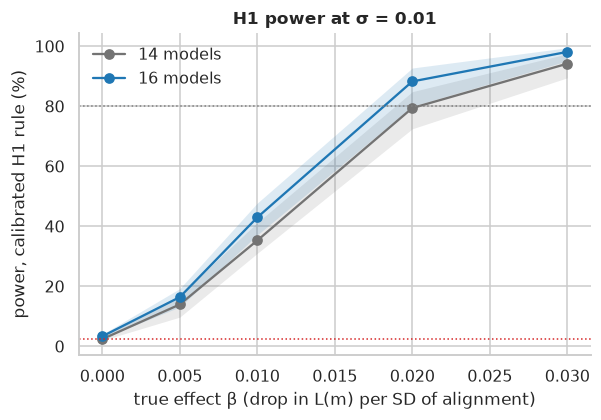

In [5]:
if not power_note:
    fig, ax = plt.subplots(figsize=(6, 3.8))
    for M, col in ((14, "0.45"), (M_EXT, "tab:blue")):
        d = pw[(pw.sigma == 0.01) & (pw.M == M)].groupby("beta").p_rule_wild.agg(["mean", "min", "max"])
        ax.plot(d.index, 100 * d["mean"], marker="o", color=col, label=f"{M} models")
        ax.fill_between(d.index, 100 * d["min"], 100 * d["max"], color=col, alpha=0.15, lw=0)
    ax.axhline(80, ls=":", color="0.5", lw=1)
    ax.axhline(2.5, ls=":", color="tab:red", lw=1)
    ax.set_xlabel("true effect β (drop in L(m) per SD of alignment)")
    ax.set_ylabel("power, calibrated H1 rule (%)")
    ax.set_title("H1 power at σ = 0.01")
    ax.legend(frameon=False)
    save(fig, "M3_power_14_vs_extended")
    plt.show()

## Facts

In [6]:
facts = {"extras": extras.model.tolist(), "models": 14 + len(extras), "families": f02["final_families"],
         "reps": POWER_REPS, "boot": POWER_BOOT, "seed": POWER_SEED,
         "numpy": np.__version__, "pandas": pd.__version__}
if not power_note:
    facts.update(M_ext=M_EXT, gain_points_calibrated_sigma01={str(k): round(v, 1) for k, v in gain.items()},
                 false_positive_pct={f"M{M}": {c: round(100 * float(fp.loc[M, (c, "mean")]), 1)
                                                for c in ("p_rule", "p_rule_wild")} for M in fp.index})
else:
    facts["note"] = power_note
json.dump(facts, open(os.path.join(OUT, "facts_02b.json"), "w"), indent=1)
for k, v in facts.items():
    print(f"{k:34s} {v}")

extras                             ['w600k_r50', 'IRV1-casia']
models                             16
families                           12
reps                               800
boot                               499
seed                               1
numpy                              1.26.4
pandas                             3.0.6
M_ext                              16
gain_points_calibrated_sigma01     {'0.01': 7.7, '0.02': 8.9}
false_positive_pct                 {'M14': {'p_rule': 0.6, 'p_rule_wild': 2.6}, 'M16': {'p_rule': 1.2, 'p_rule_wild': 3.1}}
